# 1. Làm sạch dữ liệu

**Phạm vi:** `state`, `cityname`, `latitude`, `longitude`, `time` và dữ liệu trùng lặp.

Các bước:
1. Đọc dữ liệu và xem nhanh
2. Loại bỏ dòng trùng lặp (trùng hoàn toàn, rồi trùng `id`)
3. Chuẩn hóa tên bang và thành phố, chỉ giữ 50 bang + DC
4. Làm sạch tọa độ (giá trị thiếu, tọa độ giả, ngoài lãnh thổ Mỹ, điền bằng trung vị thành phố)
5. Đếm số tin đăng mỗi thành phố (`city_n`)
6. Chuyển `time` sang ngày giờ, thêm `year`, `month`
7. Gom thành một hàm dùng lại được và lưu file phần

## Ghi chú cho nhóm

- Ghép file: `raw.merge(part, on="id", how="inner")` sẽ chỉ giữ các dòng đã qua làm sạch vị trí/thời gian.
- `coord_imputed = True`: tọa độ là trung vị của thành phố, không phải vị trí thật, nên cân nhắc loại khi vẽ bản đồ hay tính khoảng cách.
- Phân tích theo thành phố: lọc `city_n >= 30`.
- Đổi sang file 100K: chỉ cần sửa `DATA_PATH` ở ô đầu và chạy lại toàn bộ.

### Import thư viện

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### 1. Đọc dữ liệu

In [2]:
DATA_PATH = Path("../apartments_for_rent_classified_10K.csv")   # đổi thành ..._100K.csv nếu cần
OUT_DIR = Path("../outputs")
OUT_PATH = OUT_DIR / "clean_location_time_part.csv"

LOC_TIME_COLS = ["state", "cityname", "latitude", "longitude", "time"]

raw = pd.read_csv(DATA_PATH, sep=";", encoding="cp1252", na_values=["null", ""], keep_default_na=False, low_memory=False)

print(raw.shape)

raw[["id"] + LOC_TIME_COLS].head()

(10000, 22)


,id,state,cityname,latitude,longitude,time
0,5668626895,DC,Washington,38.9057,-76.9861,1577359415
1,5664597177,IN,Evansville,37.9680,-87.6621,1577017063
2,5668626833,VA,Arlington,38.8910,-77.0816,1577359410
3,5659918074,WA,Seattle,47.6160,-122.3275,1576667743
4,5668626759,VA,Arlington,38.8738,-77.1055,1577359401


In [3]:
# Số giá trị thiếu ở các cột phụ trách
raw[LOC_TIME_COLS].isna().sum().to_frame("so_dong_thieu")

,so_dong_thieu
state,77
cityname,77
latitude,10
longitude,10
time,0


### 2. Loại bỏ dòng trùng lặp

In [4]:
def drop_duplicates_step(df):
    # Loại bỏ trùng hoàn toàn
    n0 = len(df)
    df = df.drop_duplicates()

    # Loại bỏ trùng id, giữ id có time mới nhất
    n_exact = n0 - len(df)
    df = df.sort_values("time", ascending=False).drop_duplicates("id", keep="first")
    n_id = n0 - n_exact - len(df)
    return df.sort_index(), {"trung_hoan_toan": n_exact, "trung_id": n_id}

df, info = drop_duplicates_step(raw)
print(info, "| còn lại:", len(df))

{'trung_hoan_toan': 0, 'trung_id': 0} | còn lại: 10000


### 3.Chuẩn hóa tên bang và thành phố

In [5]:
VALID_STATES = {
    "AL","AK","AZ","AR","CA","CO","CT","DE","FL","GA","HI","ID","IL","IN","IA","KS","KY",
    "LA","ME","MD","MA","MI","MN","MS","MO","MT","NE","NV","NH","NJ","NM","NY","NC","ND",
    "OH","OK","OR","PA","RI","SC","SD","TN","TX","UT","VT","VA","WA","WV","WI","WY","DC",
}

def normalize_names(df):
    # Xóa dấu cách thừa
    df = df.copy()
    df["cityname"] = df["cityname"].str.strip().str.replace(r"\s+", " ", regex=True).str.title()
    df["state"] = df["state"].str.strip().str.upper()
    
    # Đếm giá trị khuyết
    n_missing = int((df["state"].isna() | df["cityname"].isna()).sum())
    keep = df["state"].isin(VALID_STATES) & df["cityname"].notna()
    n_invalid = int((~keep).sum()) - n_missing

    return df[keep], {"thieu_state_hoac_city": n_missing, "state_khong_hop_le": n_invalid}

df, info = normalize_names(df)
print(info, "| còn lại:", len(df), "| số bang:", df["state"].nunique(), "| số thành phố:", df.groupby(["state", "cityname"]).ngroups)


{'thieu_state_hoac_city': 77, 'state_khong_hop_le': 0} | còn lại: 9923 | số bang: 51 | số thành phố: 1769


### 4. Làm sạch tọa độ

1. **Tọa độ giả:** `(39.8163, -98.5576)` là tâm địa lý nước Mỹ (gần Lebanon, Kansas). Hệ thống rao vặt gán điểm này khi không tìm được địa chỉ, nên coi là thiếu.
2. **Ngoài khung lãnh thổ Mỹ:** vĩ độ ngoài [18, 72] hoặc kinh độ ngoài [-180, -65] (khung này bao cả Alaska và Hawaii) → coi là thiếu.
3. **Điền khuyết:** tọa độ thiếu được điền bằng **trung vị tọa độ của cùng (state, cityname)**. Cột `coord_imputed = True` đánh dấu các dòng đã điền để nhóm có thể loại ra khi phân tích không gian.
4. Dòng nào vẫn không có tọa độ (thành phố không có tin nào có tọa độ hợp lệ) thì bị loại, vì `latitude`/`longitude` là biến quan trọng cho mô hình.

Ở bước 4 ta chọn *đặt thành thiếu rồi điền* thay vì xóa ngay, để giữ lại dòng cho phần giá/diện tích của các bạn khác.

In [6]:
US_BBOX = {"lat": (18, 72), "lon": (-180, -65)}
PLACEHOLDER_COORDS = [(39.8163, -98.5576)]

def clean_coords_step(df, bbox=US_BBOX, fill_with_city_median=True, drop_missing=True):
    # Đếm số thiếu ban đầu
    df = df.copy()
    info = {"toa_do_thieu_ban_dau": int(df[["latitude", "longitude"]].isna().any(axis=1).sum())}

    # Tìm tọa độ giả
    fake = np.zeros(len(df), dtype=bool)
    for lat, lon in PLACEHOLDER_COORDS:
        fake |= (df["latitude"].round(4) == lat).to_numpy() & (df["longitude"].round(4) == lon).to_numpy()
    info["toa_do_gia"] = int(fake.sum())

    # Tìm tọa độ ngoài nước Mỹ
    outside = ~(df["latitude"].between(*bbox["lat"]) & df["longitude"].between(*bbox["lon"]))
    outside &= df[["latitude", "longitude"]].notna().all(axis=1)
    info["ngoai_lanh_tho_my"] = int(outside.sum())

    # Tọa độ sai -> Thiếu
    bad = fake | outside.to_numpy()
    df.loc[bad, ["latitude", "longitude"]] = np.nan

    # Điền missing data bằng trung vị (Trung vị có tính chống chịu với outlier tốt hơn)
    missing = df[["latitude", "longitude"]].isna().any(axis=1)
    df["coord_imputed"] = False
    if fill_with_city_median:
        for col in ["latitude", "longitude"]:
            med = df.groupby(["state", "cityname"])[col].transform("median")
            df[col] = df[col].fillna(med)
        df["coord_imputed"] = missing & df[["latitude", "longitude"]].notna().all(axis=1)
    info["da_dien_bang_trung_vi_city"] = int(df["coord_imputed"].sum())

    # Loại dòng vẫn thiếu
    still = df[["latitude", "longitude"]].isna().any(axis=1)
    info["van_thieu"] = int(still.sum())
    if drop_missing:
        df = df[~still]
    return df, info

df, info = clean_coords_step(df)
print(info, "| còn lại:", len(df))

{'toa_do_thieu_ban_dau': 0, 'toa_do_gia': 0, 'ngoai_lanh_tho_my': 0, 'da_dien_bang_trung_vi_city': 0, 'van_thieu': 0} | còn lại: 9923


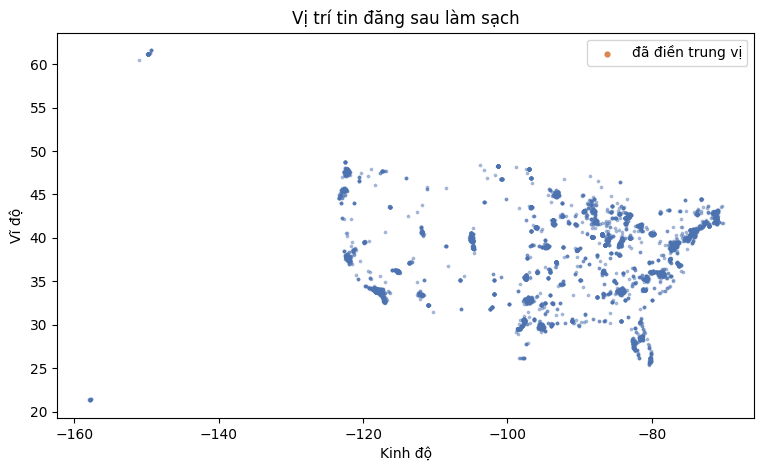

In [7]:
# Kiểm tra bằng mắt: tọa độ sau khi làm sạch phải nằm trong lãnh thổ Mỹ
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df["longitude"], df["latitude"], s=3, alpha=0.4, color="#4C72B0")
imp = df[df["coord_imputed"]]
ax.scatter(imp["longitude"], imp["latitude"], s=12, color="#DD8452", label="đã điền trung vị")
ax.set_xlabel("Kinh độ"); ax.set_ylabel("Vĩ độ"); ax.set_title("Vị trí tin đăng sau làm sạch")
ax.legend(); plt.show()

### 5. Số tin đăng mỗi thành phố (`city_n`)

Nhiều thành phố chỉ có 1–2 tin, nên thống kê theo thành phố sẽ không ổn định.
Ta **không xóa** các dòng này mà thêm cột `city_n` = số tin của cặp (state, cityname).
Khi phân tích theo thành phố, nhóm chỉ cần lọc `city_n >= 30`.

In [ ]:
MIN_CITY_N = 30

def add_city_count_step(df):
    df = df.copy()
    df["city_n"] = df.groupby(["state", "cityname"])["id"].transform("size").astype(int)
    return df

df = add_city_count_step(df)
city_sizes = df.groupby(["state", "cityname"]).size()
print(f"Số thành phố: {len(city_sizes)}, trong đó có >= {MIN_CITY_N} tin: {(city_sizes >= MIN_CITY_N).sum()}")
print(f"Số dòng thuộc các thành phố đó: {(df['city_n'] >= MIN_CITY_N).sum()} / {len(df)}")
city_sizes.sort_values(ascending=False).head(10).to_frame("so_tin")

### 6. Chuyển đổi thời gian

`time` là Unix timestamp (số giây kể từ 1970-01-01, giờ UTC). Ta chuyển sang `datetime` và thêm `year`, `month` để phân tích theo thời gian.
Cột `time` gốc vẫn được giữ lại.

In [ ]:
def convert_time_step(df):
    df = df.copy()
    df["datetime"] = pd.to_datetime(df["time"], unit="s", utc=True).dt.tz_localize(None)
    df["year"] = df["datetime"].dt.year
    df["month"] = df["datetime"].dt.month
    return df

df = convert_time_step(df)
print("Khoảng thời gian:", df["datetime"].min(), "→", df["datetime"].max())
df.groupby(["year", "month"]).size().to_frame("so_tin")

### 7. Gom thành một hàm và lưu file phần

Hàm `clean_location_time` gọi lần lượt các bước trên và trả về (dữ liệu sạch, nhật ký làm sạch).
Sau này có thể chép nguyên các hàm ở trên cùng hàm này sang file `clean_location_time.py` để import.

In [ ]:
OUTPUT_COLS = ["id", "state", "cityname", "latitude", "longitude", "coord_imputed",
               "city_n", "time", "datetime", "year", "month"]

def clean_location_time(raw, bbox=US_BBOX, fill_with_city_median=True):
    log = {"so_dong_ban_dau": len(raw)}
    df, info = drop_duplicates_step(raw); log.update(info)
    df, info = normalize_names(df); log.update(info)
    df, info = clean_coords_step(df, bbox=bbox, fill_with_city_median=fill_with_city_median); log.update(info)
    df = add_city_count_step(df)
    df = convert_time_step(df)
    log["so_dong_con_lai"] = len(df)
    return df[OUTPUT_COLS].reset_index(drop=True), log

clean, log = clean_location_time(raw)
pd.Series(log, name="so_dong").to_frame()

In [ ]:
# Kiểm tra trước khi lưu
assert clean["id"].is_unique
assert clean[["state", "cityname", "latitude", "longitude", "datetime"]].notna().all().all()
assert clean["state"].isin(VALID_STATES).all()
assert clean["latitude"].between(*US_BBOX["lat"]).all() and clean["longitude"].between(*US_BBOX["lon"]).all()

OUT_DIR.mkdir(parents=True, exist_ok=True)
clean.to_csv(OUT_PATH, index=False, encoding="utf-8-sig")
print("Đã lưu", OUT_PATH, clean.shape)
clean.head()